# 01 · Data Setup

This notebook loads the data, explains where it comes from, and checks it before any analysis. Two problems turned up in the raw file, and both get fixed here:

1. **October airports are stored as numbers.** Every October flight uses a 5-digit DOT ID (`10397`) instead of an airport code (`ATL`), so October quietly drops out of any airport or route analysis.
2. **"Delayed" needs a real definition.** I use the DOT and airline industry standard: a flight is delayed if it arrives **15+ minutes** late.

## Where the data comes from

The U.S. Department of Transportation's Bureau of Transportation Statistics (BTS) publishes on-time performance for every domestic flight run by the large U.S. carriers. Airlines report each flight's departure, arrival, delays, cancellations, and diversions to the DOT, and BTS compiles them. This project uses the full **2015** release (5.8M flights, 14 airlines, 31 columns), via the Kaggle mirror.

**To get the data:**
1. Download `flights.csv` from [Kaggle: usdot/flight-delays](https://www.kaggle.com/datasets/usdot/flight-delays)
2. Put it in the `data/` folder at the top of this repo

In [9]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.load_data import load_flights, DELAY_THRESHOLD_MIN

sns.set_theme(style="whitegrid")

In [10]:
df = load_flights("../data/flights.csv")
df.shape

October airport fix: mapped 305 airport IDs, 100.0% of October flights recovered
Loaded 5,819,079 flights | 18.6% delayed 15+ min (completed flights only)


(5819079, 35)

In [11]:
df.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,AIRLINE_NAME,SEASON,DEP_HOUR,IS_DELAYED
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,NaN,NaN,NaN,NaN,NaN,NaN,Alaska,Winter,0,0.0
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,NaN,NaN,NaN,NaN,NaN,NaN,American,Winter,0,0.0
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,NaN,NaN,NaN,NaN,NaN,NaN,US Airways,Winter,0,0.0
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,NaN,NaN,NaN,NaN,NaN,NaN,American,Winter,0,0.0
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,NaN,NaN,NaN,NaN,NaN,NaN,Alaska,Winter,0,0.0


## Problem 1: October's airport codes

In the raw file, all 486,165 October flights use numeric DOT airport IDs. Since every other month uses airport codes, any chart grouped by airport or route was silently skipping October.

**The fix (in `src/load_data.py`):** airlines fly the same flight number on the same route month to month. So for each October flight, I find the same airline, flight number, and distance in September and November, and take the airport code it lines up with most often. The check below confirms October is back.

In [12]:
october = df[df["MONTH"] == 10]
still_numeric = october["ORIGIN_AIRPORT"].str.isdigit() | october["DESTINATION_AIRPORT"].str.isdigit()
print(f"October flights still using numeric IDs: {still_numeric.sum():,} of {len(october):,}")

october["ORIGIN_AIRPORT"].value_counts().head(5)

October flights still using numeric IDs: 124 of 486,165


ORIGIN_AIRPORT
ATL    32747
ORD    27652
DFW    21044
DEN    18136
LAX    17728
Name: count, dtype: int64

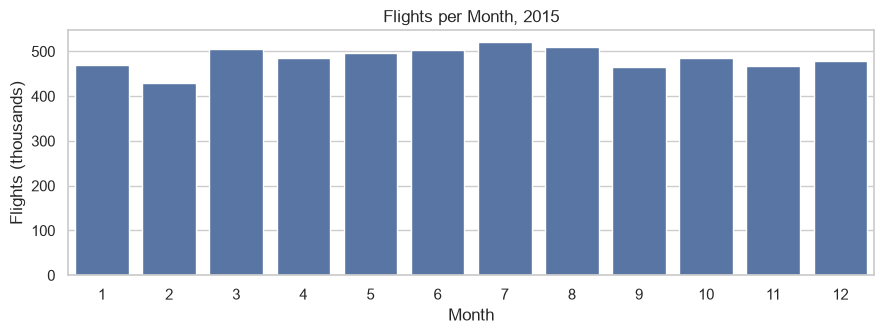

In [13]:
monthly = df.groupby("MONTH").size()

plt.figure(figsize=(9, 3.5))
sns.barplot(x=monthly.index, y=monthly.values / 1000, color="#4C72B0")
plt.title("Flights per Month, 2015")
plt.xlabel("Month")
plt.ylabel("Flights (thousands)")
plt.tight_layout()
plt.show()

## Problem 2: What counts as "delayed"

My first version counted any flight that landed even 1 minute late. The DOT, airlines, and the industry use 15 minutes, so that's what this project uses. The difference is big:

In [14]:
arrival = df["ARRIVAL_DELAY"].dropna()
print(f"Late by 1+ min:  {(arrival > 0).mean():.1%}")
print(f"Late by {DELAY_THRESHOLD_MIN}+ min: {(arrival >= DELAY_THRESHOLD_MIN).mean():.1%}  <- the number used from here on")

Late by 1+ min:  36.5%
Late by 15+ min: 18.6%  <- the number used from here on


## Completeness check

The data is already tidy: one row per flight, one column per variable. Most columns are nearly complete. The big gaps are expected:

- `CANCELLATION_REASON` is only filled in for cancelled flights.
- The five delay-cause columns (`AIRLINE_DELAY`, `WEATHER_DELAY`, and so on) are only reported for flights that arrived 15+ minutes late. They're missing for on-time flights by design, not by accident.

In [15]:
df.isna().mean().sort_values(ascending=False).head(12).map("{:.1%}".format)

CANCELLATION_REASON    98.5%
SECURITY_DELAY         81.7%
AIR_SYSTEM_DELAY       81.7%
WEATHER_DELAY          81.7%
LATE_AIRCRAFT_DELAY    81.7%
AIRLINE_DELAY          81.7%
IS_DELAYED              1.8%
AIR_TIME                1.8%
ELAPSED_TIME            1.8%
ARRIVAL_DELAY           1.8%
WHEELS_ON               1.6%
TAXI_IN                 1.6%
dtype: str

In [16]:
delayed = df[df["IS_DELAYED"] == 1]
print(f"Delayed flights with cause data: {delayed['AIRLINE_DELAY'].notna().mean():.1%}")

Delayed flights with cause data: 100.0%


## Key columns

| Column | What it means | Example |
|---|---|---|
| `AIRLINE` / `AIRLINE_NAME` | Carrier code and name | `AS` / Alaska |
| `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT` | Airport codes (October fixed) | `ANC` → `SEA` |
| `SCHEDULED_DEPARTURE` | Planned departure, local time (HHMM) | `0005` |
| `DISTANCE` | Flight distance in miles | `1448` |
| `ARRIVAL_DELAY` | Minutes late at arrival (negative = early) | `-22` |
| `CANCELLED`, `DIVERTED` | 1 if cancelled / diverted | `0` |
| `AIRLINE_DELAY`, `LATE_AIRCRAFT_DELAY`, `AIR_SYSTEM_DELAY`, `WEATHER_DELAY`, `SECURITY_DELAY` | Minutes of delay blamed on each cause | `15` |
| `IS_DELAYED` *(added)* | 1 if 15+ min late, 0 if not, blank if cancelled/diverted | `0` |
| `SEASON`, `DEP_HOUR` *(added)* | Season and scheduled departure hour | `Winter`, `0` |